In [ ]:
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YOUR_USERNAME/YOUR_REPO/blob/main/your_notebook.ipynb)

# Introduction to Google Colab and use of LLMs

Objectives:


*   **Familiarize** with the Google Colab Platform (Runtime,Cells,...).
*   Learn the **basics of programing** (Print statements).
*   Run a full **artificial intelligence pipeline** for computer vision.
*   Use LLMs to help you **debug, program and solve** questions.
*   Foment **critical thinking** against LLMs.



## 1. Insert libraries

In [1]:
!pip install --upgrade gdown

import gdown
import os
import zipfile
from pathlib import Path
import random
import copy
import matplotlib.pyplot as plt
import torch
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset, random_split
import numpy as np


#TODO together (import numpy)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 5.0 MB/s eta 0:00:00
  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.2
    Uninstalling gdown-5.2.2:
      Successfully uninstalled gdown-5.2.2


## 2. Configure the experiment

In [17]:
DATA_ROOT = Path.cwd()


TRAIN_DIR = DATA_ROOT / "data" / "Marcel-Train" # Path to the training dataset folder.
TEST_DIR = DATA_ROOT / "data" / "Marcel-Test"   # Path to the test dataset folder.
IMAGE_SIZE = 224  # Resolution to resize input images (224x224 pixels) to match MobileNet expectations.
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1) # Standard ImageNet mean normalization value per channel (RGB).
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)  # Standard ImageNet standard deviation value per channel (RGB).
BATCH_SIZE = 64 # Number of training images processed together in one step/batch on the GPU.
EPOCHS = 150 # Maximum number of full passes through the training dataset.
SEED = 42 # Random seed to guarantee reproducibility of the results and weight initializations.
HEAD_LR = 3e-3 # Learning rate used to optimize the weights of our new classification head.
BACKBONE_LR = 5e-3 # Learning rate used to fine-tune the deeper pre-trained layers of MobileNet.
PATIENCE_EARLY_STOPPING = 10 # Stop training if the validation loss does not improve for this many consecutive epochs.

## 3. Get the data

In [10]:

# Create the base data directory if it doesn't exist
DATA_ROOT.mkdir(parents=True, exist_ok=True)
base_data_dir = DATA_ROOT / "data"
base_data_dir.mkdir(parents=True, exist_ok=True)

# Google Drive ZIP File URLs provided
train_zip_url = "https://drive.google.com/file/d/1cFTaz6IN5Mlwa0VGjVmeQ-aCoEyV_opV/view?usp=sharing"
test_zip_url = "https://drive.google.com/file/d/1ZyoBqf99N0RbM1P_jkcjA6tWMJwYPNw4/view?usp=sharing"

# Temporary paths for downloaded ZIP files directly under DATA_ROOT
train_zip_path = DATA_ROOT / "train.zip"
test_zip_path = DATA_ROOT / "test.zip"

# Download and extract Training ZIP directly into DATA_ROOT / "data"
print("Downloading training ZIP...")
gdown.download(url=train_zip_url, output=str(train_zip_path), quiet=False)
print("Extracting training data...")
with zipfile.ZipFile(train_zip_path, 'r') as zip_ref:
    zip_ref.extractall(base_data_dir)
os.remove(train_zip_path)

# Download and extract Testing ZIP directly into DATA_ROOT / "data"
print("Downloading testing ZIP...")
gdown.download(url=test_zip_url, output=str(test_zip_path), quiet=False)
print("Extracting testing data...")
with zipfile.ZipFile(test_zip_path, 'r') as zip_ref:
    zip_ref.extractall(base_data_dir)
os.remove(test_zip_path)

print("Downloads and extraction completed successfully!")

Downloading...
From: https://drive.google.com/uc?id=1cFTaz6IN5Mlwa0VGjVmeQ-aCoEyV_opV
To: /content/train.zip
100%|██████████| 16.5M/16.5M [00:00<00:00, 29.5MB/s]


Extracting training data...


Downloading...
From: https://drive.google.com/uc?id=1ZyoBqf99N0RbM1P_jkcjA6tWMJwYPNw4
To: /content/test.zip
100%|██████████| 6.52M/6.52M [00:00<00:00, 14.5MB/s]

Extracting testing data...
Downloads and extraction completed successfully!


## 4. Preprocessing data

In [11]:

# Set random seeds for reproducibility
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Configure device to use the gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Simple PyTorch Dataset to load images and preprocess on the fly
class HandGestureDataset(Dataset):
    def __init__(self, folder_path):
        self.folder_path = Path(folder_path)
        self.image_paths = []
        self.labels = []

        # Identify subdirectory class names (sorted alphabetically)
        self.class_names = sorted([d.name for d in self.folder_path.iterdir() if d.is_dir()])
        self.class_to_idx = {name: idx for idx, name in enumerate(self.class_names)}

        # Define supported image file extensions (handling .ppm, .pgm, etc.)
        supported_extensions = {".ppm", ".pgm", ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

        for class_name in self.class_names:
            class_dir = self.folder_path / class_name
            for img_path in class_dir.rglob("*"):
                if img_path.suffix.lower() in supported_extensions:
                    self.image_paths.append(img_path)
                    self.labels.append(self.class_to_idx[class_name])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        # Load image and convert to RGB
        img = Image.open(img_path).convert("RGB")

        # Resize to IMAGE_SIZE
        img_resized = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)

        # Convert to tensor and scale pixels to [0, 1]
        pixels = np.array(img_resized, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(pixels).permute(2, 0, 1)

        # Normalize with ImageNet stats
        tensor = (tensor - IMAGENET_MEAN) / IMAGENET_STD
        return tensor, label

# Instantiate the training dataset and the independent test dataset
full_train_dataset = HandGestureDataset(TRAIN_DIR)
test_dataset = HandGestureDataset(TEST_DIR)
class_names = full_train_dataset.class_names

# Perform 95% training / 5% validation split on the training directory dataset
train_size = int(0.95 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

# Construct standard PyTorch DataLoaders IMPORTANT PART be careful with the names
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

# Print metrics and class balances for students
print(f"Classes: {class_names}")
print(f"Total training directory images: {len(full_train_dataset)}")
print(f"  -> Training split (95%): {len(train_dataset)} images")
print(f"  -> Validation split (5%): {len(val_dataset)} images")
print(f"Independent test images: {len(test_dataset)}")

# Quick sanity check on the loaded dataset dimensions
sample_tensor, sample_label = train_dataset[0]
print(f"\nSample preprocessed tensor shape: {sample_tensor.shape}")

Using device: cuda
Classes: ['A', 'Five', 'V']
Total training directory images: 278
  -> Training split (95%): 264 images
  -> Validation split (5%): 14 images
Independent test images: 326

Sample preprocessed tensor shape: torch.Size([3, 224, 224])


## 5. Train the model

In [12]:
# 1. Model Creation & Transfer Learning Setup
# Load pre-trained weights from ImageNet dataset to give our model a baseline understanding of shapes and features.
weights = MobileNet_V3_Small_Weights.DEFAULT
model = mobilenet_v3_small(weights=weights)

# Freeze the initial feature extraction layers so we don't destroy their pre-trained knowledge.
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Unfreeze (fine-tune) only the last 3 feature blocks to adapt higher-level patterns to our hand gesture dataset.
for parameter in model.features[-3:].parameters():
    parameter.requires_grad = True

# 2. Custom Classification Head
# Replace the final classification layer with a custom architecture mapping features to our target classes.
model.classifier = nn.Sequential(
    nn.Linear(model.classifier[0].in_features, 64),
    nn.Hardswish(),
    nn.Dropout(p=0.6), # Dropout randomly deactivates neurons during training to prevent overfitting
    nn.Linear(64, len(class_names)),
)

# Transfer the model parameters to the GPU if available for faster hardware-accelerated training.
model = model.to(device)
print("Backbone: MobileNetV3-Small (ImageNet pretrained; last 3 feature blocks fine-tuned)")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# 3. Training Components: Loss, Optimizer, and Scheduler
# Loss Function: Measures how 'wrong' the model's predictions are compared to the actual labels.
loss_fn = nn.CrossEntropyLoss()

# Optimizer: Adjusts model weights step-by-step using calculated gradients to minimize the loss.
optimizer = torch.optim.AdamW(
    [
        {"params": model.features[-3:].parameters(), "lr": BACKBONE_LR},
        {"params": model.classifier.parameters(), "lr": HEAD_LR},
    ],
    weight_decay=1e-4,
)

# Learning Rate Scheduler: Automatically decreases the learning rate when validation loss plateaus
# to allow the model to make finer, more stable weight adjustments.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=4, threshold=1e-3,
    cooldown=1, min_lr=1e-6,
)

# Metrics History Initialization
history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_loss = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0

# 4. Training and Validation Loop
for epoch in range(EPOCHS):
    # --- TRAINING PHASE ---
    model.train()
    model.features.eval() # Keep batch normalization in backbone stable during fine-tuning
    train_loss_sum = 0.0
    train_correct = 0
    train_seen = 0

    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Reset gradients from the previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass: Generate predictions
        logits = model(images)
        loss = loss_fn(logits, labels)

        # Backward pass: Compute gradients (backpropagation)
        loss.backward()

        # Optimization step: Update weights
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_seen += labels.size(0)

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_seen = 0

    # Deactivate gradient tracking since we are evaluating, saving memory and compute
    with torch.inference_mode():
        for images, labels in test_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            loss = loss_fn(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (logits.argmax(dim=1) == labels).sum().item()
            val_seen += labels.size(0)

    # 5. Calculate & Log Metrics
    train_loss = train_loss_sum / train_seen
    train_accuracy = train_correct / train_seen
    val_loss = val_loss_sum / val_seen
    val_accuracy = val_correct / val_seen

    scheduler.step(val_loss)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # 6. Early Stopping & Checkpoint Saving
    # If validation performance improves, save the weights and reset the early stopping counter
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1
        epochs_without_improvement = 0
    else:
        # Stop training early if validation performance doesn't improve for sequential epochs
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1:03d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.1%} | "
        f"val loss {val_loss:.4f}, accuracy {val_accuracy:.1%} | "
        f"lr {optimizer.param_groups[0]['lr']:.2e} | "
        f"best epoch {best_epoch}"
    )
    if epochs_without_improvement >= PATIENCE_EARLY_STOPPING:
        print(f"Early stopping: validation loss did not improve for {PATIENCE_EARLY_STOPPING} epochs.")
        break

if best_state is None:
    raise RuntimeError("Training ended without a valid best model checkpoint.")
model.load_state_dict(best_state)
print(f"Restored best model from epoch {best_epoch} (validation loss {best_val_loss:.4f}).")

# 7. Final Independent Test Evaluation
model.eval()
test_loss_sum = 0.0
test_correct = 0
test_seen = 0
class_correct = torch.zeros(len(class_names), dtype=torch.long)
class_seen = torch.zeros(len(class_names), dtype=torch.long)
with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        loss = loss_fn(logits, labels)
        predictions = logits.argmax(dim=1)

        test_loss_sum += loss.item() * labels.size(0)
        test_correct += (predictions == labels).sum().item()
        test_seen += labels.size(0)
        for class_index in range(len(class_names)):
            mask = labels == class_index
            class_correct[class_index] += (predictions[mask] == labels[mask]).sum().cpu()
            class_seen[class_index] += mask.sum().cpu()

test_loss = test_loss_sum / test_seen
test_accuracy = test_correct / test_seen
print(f"Final independent test loss: {test_loss:.4f} | accuracy: {test_accuracy:.1%}")
print("Test accuracy per class:")
class_accuracies = []
for class_index, name in enumerate(class_names):
    accuracy = class_correct[class_index].item() / class_seen[class_index].item()
    class_accuracies.append(accuracy)
    print(f"  {name}: {accuracy:.1%} ({class_correct[class_index].item()}/{class_seen[class_index].item()})")
print(f"Balanced test accuracy: {np.mean(class_accuracies):.1%}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 189MB/s]


Backbone: MobileNetV3-Small (ImageNet pretrained; last 3 feature blocks fine-tuned)
Trainable parameters: 681,763
Epoch 001/150 | train loss 1.5247, accuracy 27.3% | val loss 1.2841, accuracy 29.1% | lr 5.00e-03 | best epoch 1
Epoch 002/150 | train loss 1.5206, accuracy 15.3% | val loss 1.0714, accuracy 34.4% | lr 5.00e-03 | best epoch 2
Epoch 003/150 | train loss 1.1716, accuracy 18.4% | val loss 1.1308, accuracy 29.1% | lr 5.00e-03 | best epoch 2
Epoch 004/150 | train loss 1.2393, accuracy 25.8% | val loss 1.0978, accuracy 30.4% | lr 5.00e-03 | best epoch 2
Epoch 005/150 | train loss 1.3334, accuracy 20.9% | val loss 1.1801, accuracy 29.1% | lr 5.00e-03 | best epoch 2
Epoch 006/150 | train loss 1.2941, accuracy 18.4% | val loss 1.1095, accuracy 29.1% | lr 5.00e-03 | best epoch 2
Epoch 007/150 | train loss 1.1462, accuracy 25.2% | val loss 1.0748, accuracy 31.9% | lr 2.50e-03 | best epoch 2
Epoch 008/150 | train loss 1.0902, accuracy 36.5% | val loss 0.9852, accuracy 47.2% | lr 2.50e-

## 6. Train vs Test accuracy and loss curves

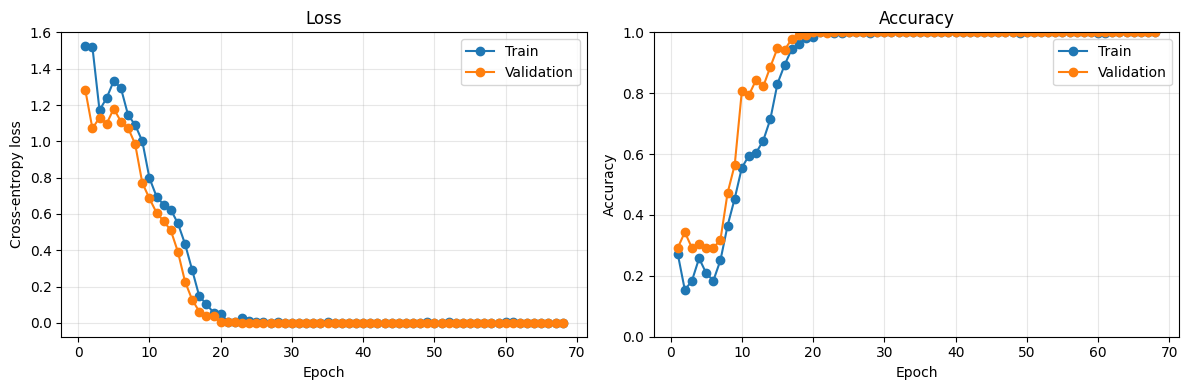

Best epoch selected using the validation split: 58
Independent test split accuracy: 100.0%


In [13]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Best epoch selected using the validation split: {best_epoch}")
print(f"Independent test split accuracy: {test_accuracy:.1%}")

## 7. Performance of the model

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           A       1.00      1.00      1.00        97
        Five       1.00      1.00      1.00       134
           V       1.00      1.00      1.00        95

    accuracy                           1.00       326
   macro avg       1.00      1.00      1.00       326
weighted avg       1.00      1.00      1.00       326



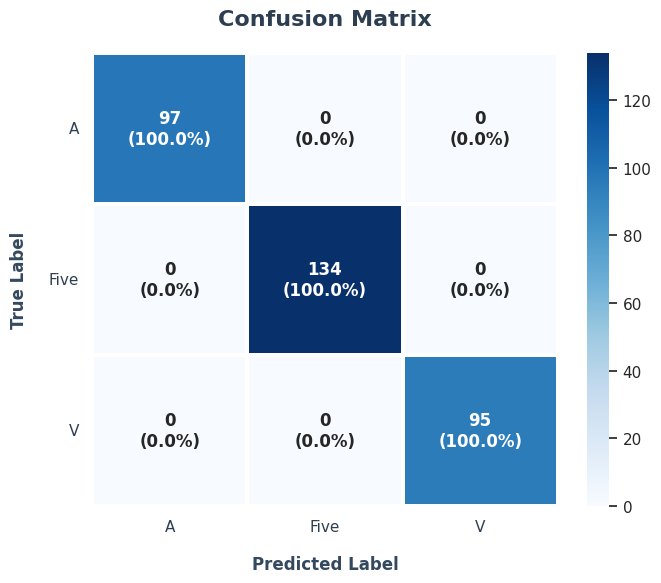

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import torch

# Ensure the model is in evaluation mode
model.eval()

all_preds = []
all_labels = []

# Get predictions from the test loader
with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# 1. Print the Classification Report as clean text for easy copy-pasting
print("=== CLASSIFICATION REPORT ===")
report = classification_report(all_labels, all_preds, target_names=class_names)
print(report)

# 2. Compute the confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Compute percentages for annotation
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

# Create annot labels with format: "count\n(percent%)"
annot_labels = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot_labels[i, j] = f"{cm[i, j]:,}\n({cm_percent[i, j]:.1f}%)"

# Set up elegant plotting parameters
fig = plt.figure(figsize=(7, 6), dpi=100)
sns.set_theme(style="white")

# Use an elegant blue/teal color palette
ax = sns.heatmap(
    cm,
    annot=annot_labels,
    fmt="",
    cmap="Blues",
    cbar=True,
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 12, "weight": "bold"},
    linewidths=1.5,
    linecolor="white"
)

# Style the titles and labels
plt.title("Confusion Matrix", fontsize=16, pad=20, weight="bold", color="#2c3e50")
plt.xlabel("Predicted Label", fontsize=12, labelpad=15, weight="semibold", color="#34495e")
plt.ylabel("True Label", fontsize=12, labelpad=15, weight="semibold", color="#34495e")

# Clean up the axis ticks styling
plt.xticks(fontsize=11, color="#2c3e50")
plt.yticks(fontsize=11, color="#2c3e50", rotation=0)

plt.tight_layout()

plt.show()

## 8. Prediction's visualization

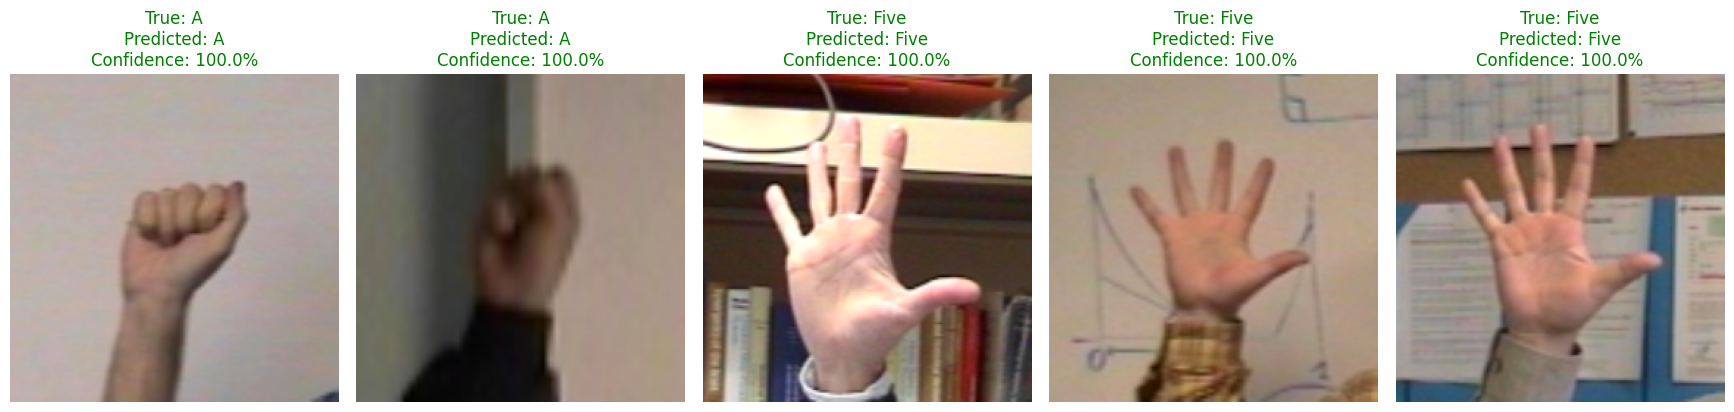

In [15]:
model.eval()
rng = random.Random(SEED)
sample_indices = rng.sample(range(len(test_dataset)), k=min(5, len(test_dataset)))
fig, axes = plt.subplots(1, len(sample_indices), figsize=(3.5 * len(sample_indices), 4))
axes = np.atleast_1d(axes)

for axis, index in zip(axes, sample_indices):
    image, true_index = test_dataset[index]
    with torch.inference_mode():
        probabilities = torch.softmax(model(image.unsqueeze(0).to(device)), dim=1)[0]
    confidence, predicted_index = probabilities.max(dim=0)
    true_name = class_names[true_index]
    predicted_name = class_names[predicted_index.item()]
    color = "green" if predicted_index.item() == true_index else "red"
    display_image = image * IMAGENET_STD + IMAGENET_MEAN
    display_image = display_image.clamp(0, 1).permute(1, 2, 0).numpy()
    axis.imshow(display_image)
    axis.set_title(
        f"True: {true_name}\nPredicted: {predicted_name}\nConfidence: {confidence.item():.1%}",
        color=color,
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

## 9. Validation with real data

### Option A: Webcam Live Test
Click the button below to turn on your laptop's camera, take a picture of your hand gesture, and test the model live!

In [ ]:
import io
import base64
from IPython.display import display, Javascript, HTML
from google.colab.output import eval_js
import ipywidgets as widgets
from PIL import Image
import cv2
import numpy as np
import torch

# HTML/JS Code to handle real-time video stream and callback Python
HTML_CAMERA_STREAM = """
<div style="border: 1px solid #ccc; padding: 10px; border-radius: 8px; max-width: 450px; background: #fafafa;">
    <h3 style="margin-top: 0; color: #2c3e50;">Live Camera Feed</h3>
    <video id="video" width="400" height="300" autoplay playsinline style="border-radius: 4px; background: #222;"></video>
    <div style="margin-top: 10px; display: flex; gap: 10px;">
        <button id="startBtn" style="padding: 8px 16px; background: #27ae60; color: white; border: none; border-radius: 4px; cursor: pointer;">Start Real-Time Stream</button>
        <button id="stopBtn" style="padding: 8px 16px; background: #c0392b; color: white; border: none; border-radius: 4px; cursor: pointer;" disabled>Stop Stream</button>
    </div>
    <div id="prediction-box" style="margin-top: 15px; font-size: 18px; font-weight: bold; color: #2980b9; min-height: 40px;">
        Status: Ready
    </div>
</div>
"""

# Global variable to check if streaming is running
streaming_active = False

def run_live_inference(image_base64):
    """This helper receives base64 frame data from JS, runs PyTorch model and returns text predictions"""
    global streaming_active
    if not streaming_active:
        return ""

    try:
        # Decode base64 image
        img_data = base64.b64decode(image_base64.split(',')[1])
        pil_img = Image.open(io.BytesIO(img_data)).convert("RGB")

        # Resize and preprocess manually
        resized_image = pil_img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
        pixels = np.array(resized_image, dtype=np.float32) / 255.0
        tensor = torch.from_numpy(pixels).permute(2, 0, 1)
        tensor = (tensor - IMAGENET_MEAN) / IMAGENET_STD
        tensor_batch = tensor.unsqueeze(0).to(device)

        # Evaluate model
        model.eval()
        with torch.inference_mode():
            outputs = model(tensor_batch)
            probabilities = torch.softmax(outputs, dim=1)[0]
            confidence, predicted_idx = probabilities.max(dim=0)

        predicted_class = class_names[predicted_idx.item()]
        conf_percent = confidence.item() * 100

        return f"Prediction: {predicted_class} ({conf_percent:.1f}% Confidence)"
    except Exception as e:
        return f"Error in processing frame: {str(e)}"

# Register the Python handler so Google Colab can execute it from JS
from google.colab import output
output.register_callback('notebook.run_live_inference', run_live_inference)

# Display the HTML interface
display(HTML(HTML_CAMERA_STREAM))

# Javascript to request camera, paint frames onto an offscreen canvas, and stream to Python
js_stream = Javascript("""
(async function() {
    const video = document.getElementById('video');
    const startBtn = document.getElementById('startBtn');
    const stopBtn = document.getElementById('stopBtn');
    const predBox = document.getElementById('prediction-box');
    let stream = null;
    let intervalId = null;

    // Create offscreen canvas to capture video frames
    const canvas = document.createElement('canvas');
    canvas.width = 300;
    canvas.height = 225;
    const ctx = canvas.getContext('2d');

    startBtn.onclick = async () => {
        try {
            stream = await navigator.mediaDevices.getUserMedia({ video: { width: 300, height: 225 } });
            video.srcObject = stream;
            await video.play();

            startBtn.disabled = true;
            stopBtn.disabled = false;
            predBox.innerText = "Initializing real-time stream...";

            // Set global python flag
            await google.colab.kernel.invokeFunction('notebook.run_live_inference', [], {});
            window.isStreaming = true;

            // Run loop
            intervalId = setInterval(async () => {
                if (!window.isStreaming) return;
                ctx.drawImage(video, 0, 0, canvas.width, canvas.height);
                const dataUrl = canvas.toDataURL('image/jpeg', 0.6);

                // Invoke prediction in python asynchronously
                const result = await google.colab.kernel.invokeFunction(
                    'notebook.run_live_inference',
                    [dataUrl],
                    {}
                );
                if (result && result.data && result.data['text/plain']) {
                    predBox.innerText = result.data['text/plain'].replace(/['\"]/g, "");
                }
            }, 250); // Predict 4 times a second

        } catch (err) {
            predBox.innerText = "Error starting camera: " + err.toString();
        }
    };

    stopBtn.onclick = () => {
        window.isStreaming = false;
        if (intervalId) clearInterval(intervalId);
        if (stream) {
            stream.getTracks().forEach(track => track.stop());
        }
        video.srcObject = null;
        startBtn.disabled = false;
        stopBtn.disabled = true;
        predBox.innerText = "Stream stopped.";
    };
})();
""")

# Activate the backend active state flag and start Javascript listener
streaming_active = True
display(js_stream)

### Option B: Local File Upload
Use this option to upload any existing image file from your computer (e.g., a photo of your hand) to see how the model classifies it!

In [ ]:
import io
import ipywidgets as widgets
from PIL import Image
import torch
import numpy as np
import matplotlib.pyplot as plt

# Helper function to preprocess, predict, and display the custom image
def predict_and_display(pil_img, title="Uploaded Image"):
    # Preprocess the PIL Image manually to match training specifications
    resized_image = pil_img.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    pixels = np.array(resized_image, dtype=np.float32) / 255.0

    # Normalize (HWC to CHW tensor, then subtract mean and divide by std)
    tensor = torch.from_numpy(pixels).permute(2, 0, 1)
    tensor = (tensor - IMAGENET_MEAN) / IMAGENET_STD
    tensor_batch = tensor.unsqueeze(0).to(device)

    # Forward pass to get predictions
    model.eval()
    with torch.inference_mode():
        outputs = model(tensor_batch)
        probabilities = torch.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = probabilities.max(dim=0)

    predicted_name = class_names[predicted_idx.item()]
    conf_percent = confidence.item() * 100

    # Display the processed image along with predictions
    plt.figure(figsize=(4, 4))
    plt.imshow(pixels)  # Show the raw resized pixels [0, 1] range safely
    plt.title(f"{title}\nPredicted: {predicted_name} ({conf_percent:.1f}%)", fontsize=12, weight="bold", color="green")
    plt.axis("off")
    plt.show()

# OPTION B: IMAGE UPLOAD WORKFLOW
uploader = widgets.FileUpload(
    accept='image/*',  # Accept any image files
    multiple=False,     # Accept single image only
    description="📤 Upload Hand Image",
    layout=widgets.Layout(width='200px', height='40px')
)

def on_upload_change(change):
    if not uploader.value:
        return

    # Handle ipywidgets file structures safely across different versions
    if isinstance(uploader.value, dict):
        # Dictionary structure (older widgets format or specific environments)
        filename = list(uploader.value.keys())[0]
        content = uploader.value[filename]['content']
    else:
        # Tuple / List structure (newer ipywidgets v8 format)
        uploaded_file = uploader.value[0]
        content = uploaded_file['content']

    # Read file contents and display prediction
    pil_img = Image.open(io.BytesIO(content))
    predict_and_display(pil_img, "Uploaded Image")

    # Reset the uploader value so students can upload different files
    uploader.value = ()

uploader.observe(on_upload_change, names='value')
display(uploader)

---
# 🕵️ Activity: Find what's wrong with this notebook

## The mission
This notebook trains an AI to recognize hand gestures (**A**, **Five**, **V**). It runs without crashing and gives you results, **but it has 2 major errors hidden in it, plus one thing that can be improved.** Your job is to find them and fix them.

## Rules
- Work in your group, each on your own computer.
- You can use **anything**: Google, books, classmates, and any LLM (ChatGPT, Gemini, Claude...). Copy and paste whatever you want. You can also write new code yourself or ask an LLM to generate it.
- You can change **one or two things at a time**. Write down what you changed, so you know what caused each result.
- You **don't** need to rerun the whole notebook. Rerun the cell you changed, then the cells that depend on it (each part tells you which).
- The number to watch is the **accuracy**. Write it down after every run.
- After each part, **stop and call the professor** before continuing.
- **You don't need to rerun section 3 ("Get the data").** It downloads the data again and takes a long time.

## Part 1: The results
Run the notebook from the top, as we did together. Look at the accuracy in the final test line (section 5) and in the classification report (section 7).

**Your task:** Paste the results into an LLM and ask what it thinks. Then decide for yourself: do you agree with it? Find the problem, fix it, and write down the new accuracy.

**Rerun after your fix:** the training cell (section 5) → the classification report (section 7). The predictions (section 8) are optional.

<details>
<summary>💡 Hint 1 (open only after trying)</summary>

Is a perfect score of 1.00 in every class normal for a real model? What could make it that perfect?
</details>

<details>
<summary>💡 Hint 2</summary>

Read the training cell. The model learns from some data and is checked with other data. Look at the names of the data loaders in each loop. There is more than one loop.
</details>

<details>
<summary>💡 Hint 3 (last resort)</summary>

Section 4 creates three loaders: `train_loader`, `val_loader` and `test_loader`. Each one should be used for a different purpose. Which loop should use which?
</details>

✋ **STOP: call the professor to check your fix before moving on.**

## Part 2: The configuration
Your result looks more believable now. But can the model improve?

**Your task:** Look at the configuration cell (section 2). Ask an LLM which values look suspicious and why. Try a change and compare the accuracy.

**Rerun after your change:** the configuration cell (section 2) → the training cell (section 5) → the classification report (section 7).

<details>
<summary>💡 Hint 1</summary>

Look at the two learning rates. The backbone is already pretrained and only needs small adjustments, while the head is new. Does the relationship between the two values make sense?
</details>

<details>
<summary>💡 Hint 2</summary>

Try lowering `BACKBONE_LR` by a lot (for example 10 to 50 times smaller).
</details>

✋ **STOP: call the professor before continuing.**

## Part 3: Is it still too good to be true?
Your accuracy improved. **Be suspicious anyway.** A good number is a claim to check, not proof that everything is fine.

**Your task:** Think about how the training data and the test data could still be connected. Ask an LLM how you could check it, and then check it yourself with code. Don't trust an answer you haven't verified.

**Rerun after your fix:** the preprocessing cell (section 4) → the training cell (section 5) → the classification report (section 7). In section 4, check that the number of training images changed.

<details>
<summary>💡 Hint 1</summary>

Could the same image exist in both the training folder and the test folder?
</details>

<details>
<summary>💡 Hint 2</summary>

Two identical files have the same "fingerprint" (a hash). Write code that compares the fingerprints of all the files in `TRAIN_DIR` and `TEST_DIR`.
</details>

<details>
<summary>💡 Hint 3 (last resort)</summary>

This code finds the images that appear in both folders.

```python
import hashlib
from pathlib import Path

def hash_map(folder):
    d = {}
    for p in Path(folder).rglob("*"):
        if p.is_file():
            d.setdefault(hashlib.md5(p.read_bytes()).hexdigest(), []).append(p)
    return d

train_map, test_map = hash_map(TRAIN_DIR), hash_map(TEST_DIR)
shared = set(train_map) & set(test_map)
print("Identical images in both folders:", len(shared))

for h in list(shared)[:5]:
    print("TRAIN:", train_map[h])
    print("TEST: ", test_map[h])
```
</details>

✋ **STOP: call the professor to discuss your final result.**

## 📝 Your record

| Step | What did you change? | Accuracy | What did the LLM say about this result? |
|------|----------------------|----------|-----------------------------------------|
| Original | nothing | | |
| After Part 1 | || |
| After Part 2 | | | |
| After Part 3 | | | |

## 🧠 Final questions (answer in your group)
1. Which number did you trust, and what should have warned you?
2. Did the LLM ever say a result was good when it wasn't? Did it find all the problems by itself?
3. Look at the last column of your record. Which LLM answer sounded the most confident, and was it correct?
4. Name one thing the LLM said that you verified, and one thing you didn't.
5. If an AI (or a person) tells you "this result looks good", what will you do next time?

## Part 4: Bonus
The activity is finished. If you want to learn more, we can improve the model even further. **Ask the professor.**